In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sb
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.svm import SVR

In [2]:
data_fin_imprt = pd.read_csv("final.csv", delimiter=",")

In [3]:
data_fin_imprt.head(15)

,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,3.044522,4.955827,10.366309,6,1.791759,7.581210,1960,4.727388,6.461468,0.000000,...,0,0,0,1,0,0,0,0,1,0
1,3.044522,4.394449,9.360741,5,1.945910,7.581720,1961,0.000000,6.150603,4.976734,...,0,0,0,1,0,0,0,0,1,0
2,3.044522,4.406719,9.565775,6,1.945910,7.580189,1958,4.691348,6.828712,0.000000,...,0,0,0,1,0,0,0,0,1,0
3,3.044522,4.543295,9.320181,7,1.791759,7.585281,1968,0.000000,6.971669,0.000000,...,0,0,0,1,0,0,0,0,1,0
4,4.110874,4.317488,9.534668,5,1.791759,7.599902,1998,0.000000,6.674561,0.000000,...,0,0,0,1,0,0,0,0,1,0
5,4.110874,4.369448,9.208238,6,1.945910,7.600402,1998,3.044522,6.401917,0.000000,...,0,0,0,1,0,0,0,0,1,0
6,4.795791,3.737670,8.501267,8,1.791759,7.601902,2001,0.000000,6.424869,0.000000,...,0,0,0,1,0,0,0,0,1,0
7,4.795791,3.784190,8.518392,8,1.791759,7.597396,1992,0.000000,5.575949,0.000000,...,0,0,0,1,0,0,0,0,1,0
8,4.795791,3.688879,8.592301,8,1.791759,7.598900,1996,0.000000,7.074117,0.000000,...,0,0,0,1,0,0,0,0,1,0
9,4.110874,4.110874,8.922792,7,1.791759,7.600902,1999,0.000000,0.000000,0.000000,...,0,0,0,1,0,0,0,0,1,0


In [4]:
x = data_fin_imprt.drop("SalePrice", axis=1)
y = data_fin_imprt["SalePrice"]
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [5]:
SVR_mod = SVR()
SVR_mod.fit(x_train, y_train)  # fitting the model
SVR_pred = SVR_mod.predict(x_test)  # predicting the values

In [6]:
SVR_mod_sc = SVR_mod.score(x_train, y_train)
print("Support Vector Regression Model Score  : ", round(SVR_mod_sc, 3))
r2 = r2_score(y_test, SVR_pred)  # computing and displaying the R.Sq of the model
print("R Sq. Value : ", round(r2, 2))
rfr_adj_r2 = 1 - (1 - r2) * (len(y) - 1) / (len(y) - x.shape[1] - 1)
print("Adjusted R Sq. Value is : ", round(rfr_adj_r2, 3))
mean_sq = mean_squared_error(
    y_test, SVR_pred
)  # computing and displaying the Mean square error of the model
print("Mean Square Error is : ", round(mean_sq, 3))
lin_rmse = mean_squared_error(y_test, SVR_pred, squared=False)
print("Root Mean Square Error is : ", round(lin_rmse, 3))
lin_mae = mean_absolute_error(y_test, SVR_pred)
print("Mean Absoulue Error is : ", round(lin_mae, 3))
scores_cvs = cross_val_score(SVR_mod, x, y, scoring="r2", cv=5)
print("Accuracy :", round(scores_cvs.mean() * 100, 2), "%")  # Accuracy of model

Support Vector Regression Model Score  :  0.489
R Sq. Value :  0.57
Adjusted R Sq. Value is :  0.526
Mean Square Error is :  0.079
Root Mean Square Error is :  0.282
Mean Absoulue Error is :  0.211
Accuracy : 50.28 %


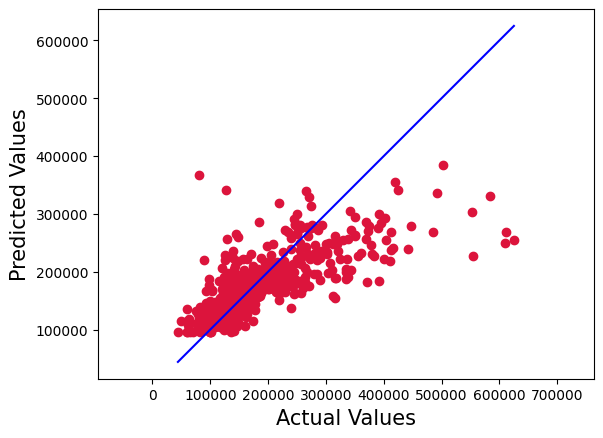

In [7]:
Actual_Price = np.expm1(y_test)
Predicted_Price = np.expm1(SVR_pred)
plt.scatter(Actual_Price, Predicted_Price, c="crimson")
p1 = max(max(Predicted_Price), max(Actual_Price))
p2 = min(min(Predicted_Price), min(Actual_Price))
plt.plot([p1, p2], [p1, p2], "b-")
plt.xlabel("Actual Values", fontsize=15)
plt.ylabel("Predicted Values", fontsize=15)
plt.axis("equal")
plt.show()

C:\Users\domin\AppData\Local\Temp\ipykernel_16280\3733621231.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sb.distplot((y_test - SVR_pred), bins=100);


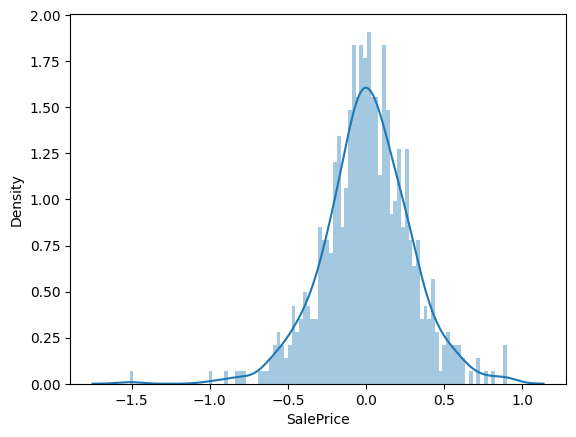

In [8]:
sb.distplot((y_test - SVR_pred), bins=100);

In [9]:
param = {"verbose": [2, 4, 6], "C": [1, 5, 10], "gamma": [0.1, 0.5]}

G_CV_lin_rid = GridSearchCV(estimator=SVR_mod, param_grid=param, cv=5)
#  using grid search method to optimise model with hyperparameter tuning

G_CV_lin_rid.fit(x_train, y_train)  # fitting the model
G_CV_lin_rid.best_params_  # displaying optimised parameters for optimal tuning of model

[LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM][LibSVM]

{'C': 5, 'gamma': 0.1, 'verbose': 2}

In [10]:
SVR_mod = SVR(gamma=0.1, C=5, verbose=2)
SVR_mod.fit(x_train, y_train)
SVR_pred = SVR_mod.predict(x_test)

[LibSVM]

In [11]:
SVR_mod_sc = SVR_mod.score(x_train, y_train)
print("Support Vector Regression Model Score  : ", round(SVR_mod_sc, 3))
r2 = r2_score(y_test, SVR_pred)  # computing and displaying the R.Sq of the model
print("R Sq. Value : ", round(r2, 2))
rfr_adj_r2 = 1 - (1 - r2) * (len(y) - 1) / (len(y) - x.shape[1] - 1)
print("Adjusted R Sq. Value is : ", round(rfr_adj_r2, 3))
mean_sq = mean_squared_error(
    y_test, SVR_pred
)  # computing and displaying the Mean square error of the model
print("Mean Square Error is : ", round(mean_sq, 3))
lin_rmse = mean_squared_error(y_test, SVR_pred, squared=False)
print("Root Mean Square Error is : ", round(lin_rmse, 3))
lin_mae = mean_absolute_error(y_test, SVR_pred)
print("Mean Absoulue Error is : ", round(lin_mae, 3))
scores_cvs = cross_val_score(SVR_mod, x, y, scoring="r2", cv=5)
print("Accuracy :", round(scores_cvs.mean() * 100, 2), "%")
# Accuracy of moadel based on parameter supplied by GridsearchCV

Support Vector Regression Model Score  :  0.946
R Sq. Value :  0.02
Adjusted R Sq. Value is :  -0.081
Mean Square Error is :  0.181
Root Mean Square Error is :  0.425
Mean Absoulue Error is :  0.332
[LibSVM][LibSVM][LibSVM][LibSVM][LibSVM]Accuracy : 0.87 %


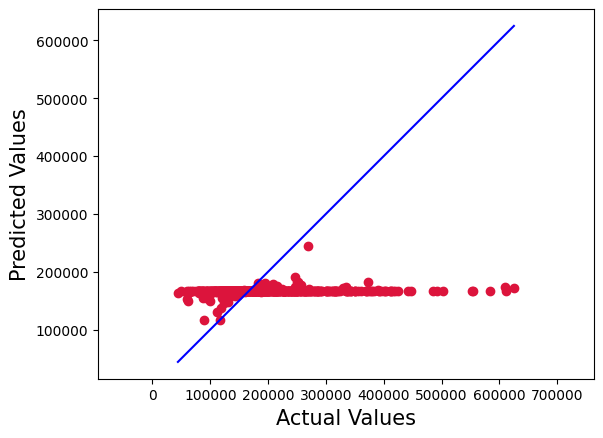

In [12]:
Actual_Price = np.expm1(y_test)
Predicted_Price = np.expm1(SVR_pred)
plt.scatter(Actual_Price, Predicted_Price, c="crimson")
p1 = max(max(Predicted_Price), max(Actual_Price))
p2 = min(min(Predicted_Price), min(Actual_Price))
plt.plot([p1, p2], [p1, p2], "b-")
plt.xlabel("Actual Values", fontsize=15)
plt.ylabel("Predicted Values", fontsize=15)
plt.axis("equal")
plt.show()

C:\Users\domin\AppData\Local\Temp\ipykernel_16280\3733621231.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sb.distplot((y_test - SVR_pred), bins=100);


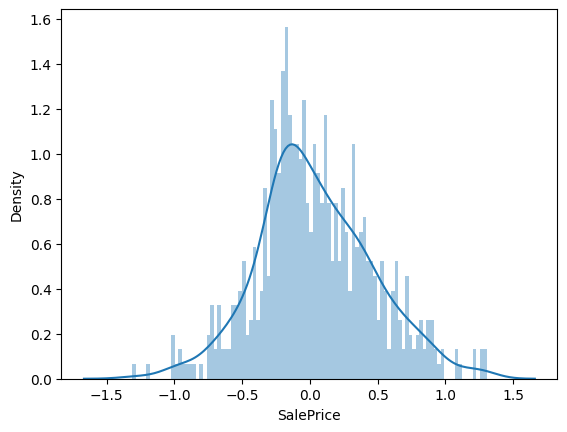

In [13]:
sb.distplot((y_test - SVR_pred), bins=100);